In [1]:
import os, json
os.chdir(os.path.expanduser("~/NLP/nlp1-emoji"))   
import pandas as pd, numpy as np
df = pd.DataFrame(json.load(open("results/project/t2/cv_results.json")))
df.groupby("system")[["macro_f1", "accuracy"]].agg(["mean", "std"]).round(3).sort_values(("macro_f1", "mean"), ascending=False)

macro_f1        accuracy       
                               mean    std     mean    std
system                                                    
logistic | bow+bigrams        0.216  0.004    0.284  0.005
weighted_mlp | indicator      0.212  0.005    0.227  0.008
logistic | indicator          0.211  0.004    0.279  0.005
weighted_mlp | bow            0.211  0.006    0.226  0.008
logistic | bow                0.209  0.004    0.277  0.004
weighted_mlp | bow+bigrams    0.201  0.019    0.230  0.009
mlp | bow+bigrams             0.195  0.024    0.306  0.006
mlp | bow                     0.186  0.006    0.308  0.005
mlp | indicator               0.186  0.006    0.309  0.006
deep_mlp | bow                0.166  0.007    0.301  0.005
deep_mlp | indicator          0.166  0.008    0.302  0.004
deep_mlp | bow+bigrams        0.129  0.029    0.294  0.007

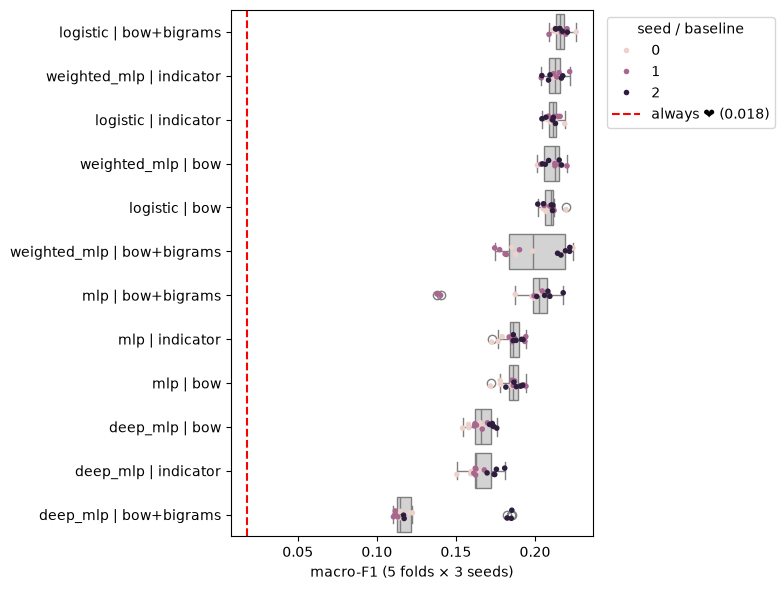

In [3]:
import seaborn as sns, matplotlib.pyplot as plt
os.makedirs("results/project/t2/figures", exist_ok=True)

order = df.groupby("system").macro_f1.mean().sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(8, 6))
sns.boxplot(data=df, y="system", x="macro_f1", order=order, color="lightgray", ax=ax)
sns.stripplot(data=df, y="system", x="macro_f1", order=order, hue="seed", size=4, ax=ax)   # the 15 dots, coloured by seed
ax.axvline(0.018, ls="--", c="red", label="always ❤ (0.018)")
ax.set_xlabel("macro-F1 (5 folds × 3 seeds)"); ax.set_ylabel("")
ax.legend(title="seed / baseline", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout(); plt.savefig("results/project/t2/figures/boxplot_macro_f1.png", dpi=200); plt.show()

In [4]:
from part1.analysis import BenavoliCorrelatedT

def scores(system):
      # sort so (seed, fold) pairs line up between systems: this is a PAIRED comparison
      return df[df.system == system].sort_values(["seed", "fold"]).macro_f1.values

ROPE = 0.01
comparisons = [   # (A, B): the question is "is B better than A?"
      ("mlp | indicator",        "weighted_mlp | indicator"),   # YOUR idea: does weighting help?
      ("mlp | bow",              "weighted_mlp | bow"),
      ("logistic | indicator",   "mlp | indicator"),            # tutorial question: linear vs MLP
      ("mlp | bow",              "deep_mlp | bow"),             # does depth help?
      ("logistic | bow",         "logistic | bow+bigrams"),     # do bigrams help?
      ("weighted_mlp | indicator", "logistic | bow+bigrams"),   # best vs second-best
  ]

rows = []
for a, b in comparisons:
      t = BenavoliCorrelatedT(scores(a), scores(b), runs=3, names=[a, b])
      p_a, p_tie, p_b = t.probs(ROPE)
      rows.append({"A": a, "B": b, "mean diff (B−A)": round(t.mean_diff, 4),
                   "P(A better)": round(p_a, 3), "P(tie)": round(p_tie, 3), "P(B better)": round(p_b, 3)})
      fig, ax = t.plot(ROPE)
      fig.savefig(f"results/project/t2/figures/rope__{a.replace(' | ', '_')}__vs__{b.replace(' | ', '_')}.png",
                  dpi=150, bbox_inches="tight")
      plt.close(fig)

rope_table = pd.DataFrame(rows)
rope_table

,A,B,mean diff (B−A),P(A better),P(tie),P(B better)
0,mlp | indicator,weighted_mlp | indicator,0.0260,0.000,0.001,0.999
1,mlp | bow,weighted_mlp | bow,0.0255,0.000,0.000,1.000
2,logistic | indicator,mlp | indicator,-0.0255,0.999,0.001,0.000
3,mlp | bow,deep_mlp | bow,-0.0195,0.990,0.010,0.000
4,logistic | bow,logistic | bow+bigrams,0.0066,0.000,0.964,0.036
5,weighted_mlp | indicator,logistic | bow+bigrams,0.0042,0.000,0.980,0.020


In [6]:
from sklearn.metrics import f1_score, accuracy_score, classification_report, confusion_matrix
from project.lib import load_tweeteval_emoji
_, _, _, names = load_tweeteval_emoji(clean=True)

BEST_ENC, BEST_MODEL = "bow+bigrams", "logistic"      # chosen from cross-validation, BEFORE looking at test
y_test = np.load("results/project/t2/y_test.npy")
preds = np.stack([np.load(f"results/project/t2/test_preds/{BEST_ENC}__{BEST_MODEL}__s{s}__f{f}.npy")
                    for s in range(3) for f in range(5)])          # shape (15 models, 50000 tweets)

  # majority vote: for each tweet, the emoji most of the 15 models predicted
vote = np.array([np.bincount(col, minlength=20).argmax() for col in preds.T])

single = [f1_score(y_test, p, average="macro") for p in preds]
print(f"single models: macro-F1 {np.mean(single):.4f} ± {np.std(single):.4f}")
print(f"ENSEMBLE:      macro-F1 {f1_score(y_test, vote, average='macro'):.4f}  accuracy {accuracy_score(y_test, vote):.4f}")
print(f"always ❤:      macro-F1 {f1_score(y_test, np.zeros_like(y_test), average='macro'):.4f}")

single models: macro-F1 0.1904 ± 0.0012
ENSEMBLE:      macro-F1 0.1948  accuracy 0.2776
always ❤:      macro-F1 0.0178


,precision,recall,f1-score,support
🎄,0.669,0.496,0.570,1545.0
❤,0.319,0.549,0.403,10798.0
🔥,0.476,0.320,0.383,3716.0
🇺🇸,0.706,0.261,0.381,1949.0
😂,0.282,0.409,0.334,4534.0
📷,0.272,0.385,0.319,1432.0
☀,0.395,0.217,0.280,1265.0
📸,0.400,0.178,0.246,2417.0
😍,0.184,0.253,0.213,4830.0
✨,0.212,0.153,0.178,2749.0


/Users/ana/NLP/nlp1-emoji/.venv/lib/python3.14/site-packages/seaborn/utils.py:61: UserWarning: Glyph 128149 (\N{TWO HEARTS}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/Users/ana/NLP/nlp1-emoji/.venv/lib/python3.14/site-packages/seaborn/utils.py:61: UserWarning: Glyph 128293 (\N{FIRE}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/Users/ana/NLP/nlp1-emoji/.venv/lib/python3.14/site-packages/seaborn/utils.py:61: UserWarning: Glyph 10024 (\N{SPARKLES}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/Users/ana/NLP/nlp1-emoji/.venv/lib/python3.14/site-packages/seaborn/utils.py:61: UserWarning: Glyph 128153 (\N{BLUE HEART}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/Users/ana/NLP/nlp1-emoji/.venv/lib/python3.14/site-packages/seaborn/utils.py:61: UserWarning: Glyph 128247 (\N{CAMERA}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/Users/ana/NLP/nlp1-emoji/.venv/lib/python3.14/site-packages/seaborn/utils.py:61: UserWarning: Glyph 127482 (\N{REGION

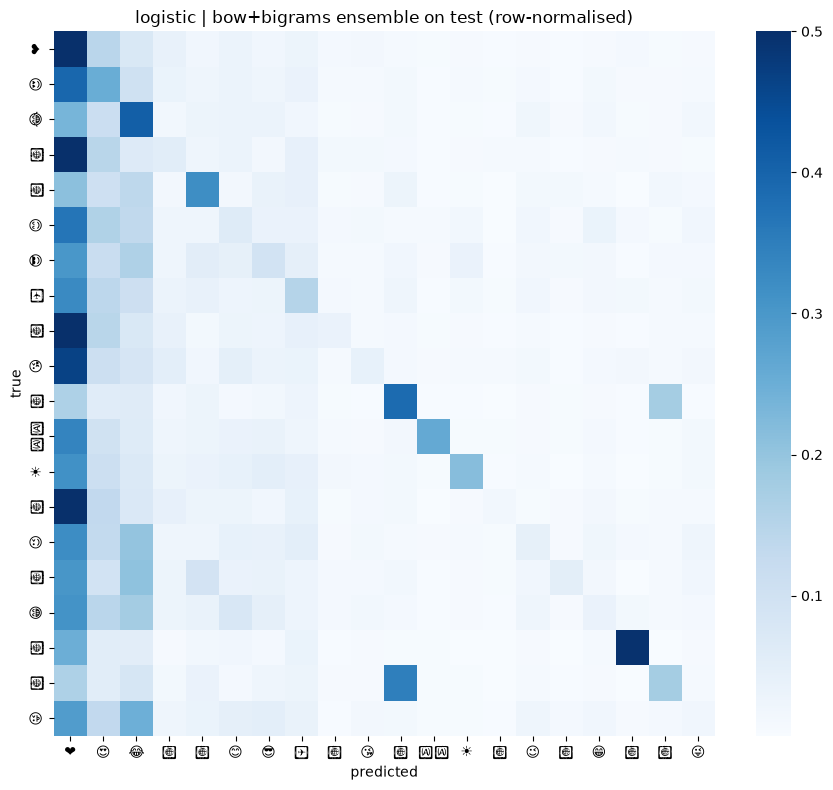

💜 → ❤: 52.2% of true 💜 tweets
💕 → ❤: 51.9% of true 💕 tweets
💙 → ❤: 51.0% of true 💙 tweets
😘 → ❤: 46.6% of true 😘 tweets
😍 → ❤: 39.5% of true 😍 tweets
😊 → ❤: 36.7% of true 😊 tweets
📸 → 📷: 34.9% of true 📸 tweets
🇺🇸 → ❤: 34.0% of true 🇺🇸 tweets
✨ → ❤: 32.7% of true ✨ tweets
😉 → ❤: 32.2% of true 😉 tweets


In [8]:
# per-emoji scores, sorted from easiest to hardest
rep = classification_report(y_test, vote, target_names=names, output_dict=True, zero_division=0)
per_class = pd.DataFrame({e: rep[e] for e in names}).T[["precision", "recall", "f1-score", "support"]]
per_class = per_class.sort_values("f1-score", ascending=False).round(3)
display(per_class)

  # confusion matrix, normalised per true emoji: row = true emoji, column = predicted
cm = confusion_matrix(y_test, vote, normalize="true")
fig, ax = plt.subplots(figsize=(9, 8))
sns.heatmap(cm, xticklabels=names, yticklabels=names, cmap="Blues", vmax=0.5, ax=ax)
ax.set_xlabel("predicted"); ax.set_ylabel("true")
ax.set_title("logistic | bow+bigrams ensemble on test (row-normalised)")
plt.tight_layout(); plt.savefig("results/project/t2/figures/confusion_matrix.png", dpi=200); plt.show()

  # the 10 most common confusions (excluding correct predictions)
off = cm.copy(); np.fill_diagonal(off, 0)
top = np.dstack(np.unravel_index(np.argsort(off.ravel())[::-1][:10], off.shape))[0]
for t, p in top:
    print(f"{names[t]} → {names[p]}: {off[t, p]*100:.1f}% of true {names[t]} tweets")